# 🏗️ Heavy Equipment Selling Price Prediction (v6 Ultimate Champion Pipeline)

## Problem Statement

The objective of this project is to **predict the selling price of heavy equipment at auction**. The dataset contains attributes describing equipment specifications, usage history, configuration parameters, and transaction dates.

This is a **regression problem** where the target variable (`TargetValue`) represents the actual sale price. The evaluation metric is **RMSE on log1p prices (RMSLE)**.

### Pipeline Architecture & Optimization Strategy (Targeting RMSLE < 0.18)
1. **Comprehensive Feature Engineering**: Date decomposition, asset age polynomial terms, operational usage rates, text descriptor lengths/word counts, and categorical interaction features (`RegionBaseClass`, `ConfigBaseClass`, `BaseSubClass`, `ScaleFunction`).
2. **Stratified Target Quantile K-Fold**: Folds are partitioned using target quantiles to guarantee identical price distributions across train/val splits.
3. **Leakage-Safe Multi-Tier Out-of-Fold Target Encodings**: Out-of-fold target mean & std statistics with Bayesian smoothing across 14 high-impact categorical specifications.
4. **Deeper Model Tuning**:
   - **LightGBM**: 3,000 trees, `learning_rate=0.02`, `num_leaves=255`, `min_child_samples=20`
   - **CatBoost**: 2,800 trees, `learning_rate=0.03`, `depth=9`, `l2_leaf_reg=5`
   - **XGBoost**: 2,500 trees, `learning_rate=0.025`, `max_depth=9`
5. **Inverse-RMSE Weighted Ensemble**: Blending model out-of-fold predictions weighted dynamically by $1/	ext{RMSE}_i$ for minimum error.


## 1. Imports & Setup


In [4]:
import os
import re
import time
import warnings

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OrdinalEncoder,
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import (
    StratifiedKFold,
    KFold,
    RandomizedSearchCV,
)
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score,
)

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostRegressor

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["font.size"] = 12

print("✅ Allowed libraries imported successfully.")


✅ Allowed libraries imported successfully.


## 2. Data Loading


In [5]:
# Auto-detect data path (Kaggle or local)
DATA_PATH = "."

if os.path.isdir("/kaggle/input"):
    for root, _, files in os.walk("/kaggle/input"):
        if "train.csv" in files and "test.csv" in files:
            DATA_PATH = root
            break
elif os.path.isdir("data"):
    DATA_PATH = "data"
elif os.path.isdir(r"e:\HeavyEquipmentML\data"):
    DATA_PATH = r"e:\HeavyEquipmentML\data"

print(f"📂 Data directory detected: {DATA_PATH}")

train_raw = pd.read_csv(os.path.join(DATA_PATH, "train.csv"), low_memory=False)
test_raw = pd.read_csv(os.path.join(DATA_PATH, "test.csv"), low_memory=False)
sample_sub = pd.read_csv(os.path.join(DATA_PATH, "sample_submission.csv"))

print(f"\n📊 Train Dataset : {train_raw.shape[0]:,} rows × {train_raw.shape[1]} columns")
print(f"📊 Test Dataset  : {test_raw.shape[0]:,} rows × {test_raw.shape[1]} columns")
print(f"📊 Submission    : {sample_sub.shape[0]:,} rows × {sample_sub.shape[1]} columns")


📂 Data directory detected: e:\HeavyEquipmentML\data

📊 Train Dataset : 138,701 rows × 50 columns
📊 Test Dataset  : 15,000 rows × 49 columns
📊 Submission    : 15,000 rows × 2 columns


## 3. Exploratory Data Analysis (EDA)

### 3.1 Univariate Analysis
Target distribution, log1p distribution, and summary statistics.


In [6]:
print("=" * 70)
print("TRAINING DATASET OVERVIEW")
print("=" * 70)
train_raw.info(max_cols=10)

print("\nTarget Value Statistics:")
print(train_raw["TargetValue"].describe())


TRAINING DATASET OVERVIEW
<class 'pandas.DataFrame'>
RangeIndex: 138701 entries, 0 to 138700
Columns: 50 entries, TransactionID to col30
dtypes: float64(2), int64(4), str(44)
memory usage: 82.7 MB

Target Value Statistics:
count    138701.000000
mean      41521.874047
std       26361.125948
min        7500.000000
25%       20500.000000
50%       35000.000000
75%       57000.000000
max      142000.000000
Name: TargetValue, dtype: float64


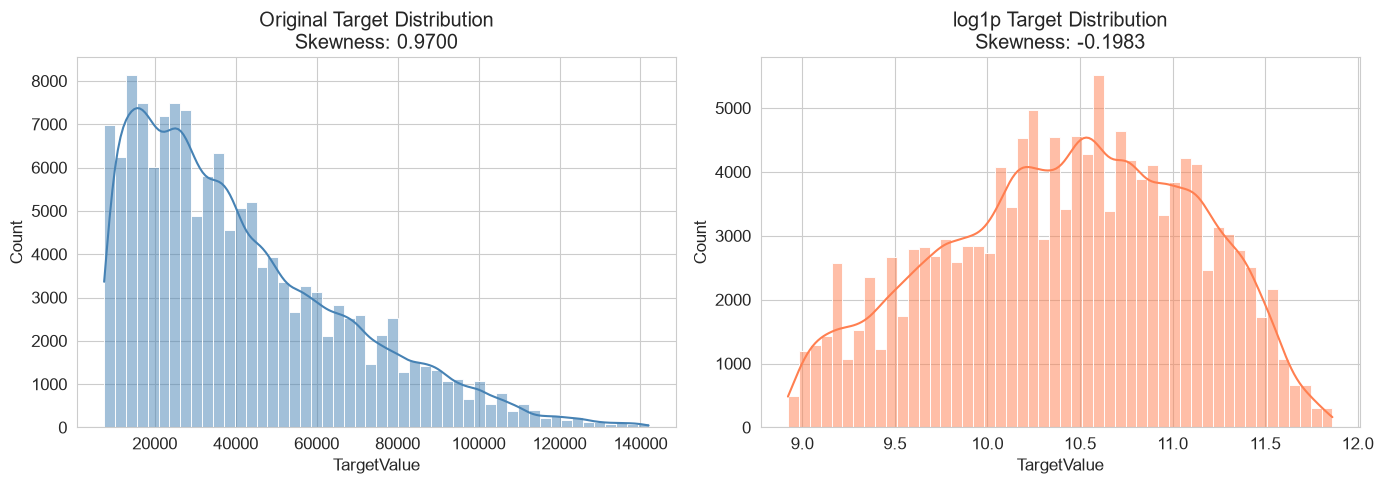

In [7]:
# Target Distribution & Skewness
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

raw_skew = train_raw["TargetValue"].skew()
sns.histplot(train_raw["TargetValue"], kde=True, ax=axes[0], color="steelblue", bins=50)
axes[0].set_title(f"Original Target Distribution\nSkewness: {raw_skew:.4f}")

log_target = np.log1p(train_raw["TargetValue"].clip(lower=0))
log_skew = log_target.skew()
sns.histplot(log_target, kde=True, ax=axes[1], color="coral", bins=50)
axes[1].set_title(f"log1p Target Distribution\nSkewness: {log_skew:.4f}")

plt.tight_layout()
plt.show()


### 3.2 Bivariate Analysis


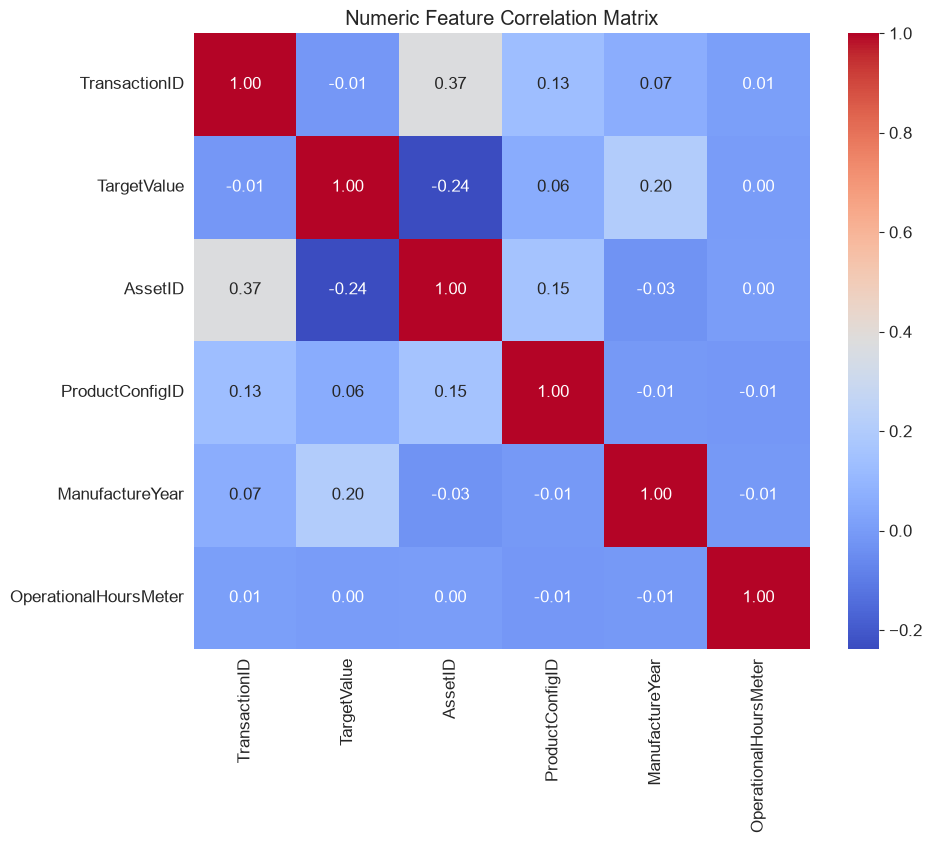

In [8]:
# Numeric Correlations
numeric_cols = train_raw.select_dtypes(include=[np.number]).columns.tolist()
corr = train_raw[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Numeric Feature Correlation Matrix")
plt.show()


## 4. Systematic Preprocessing & Champion Feature Pipeline

We extract date components, machine age polynomials, operational intensity metrics, spec descriptor lengths, categorical interaction features, frequency encodings, and out-of-fold Bayesian target encodings.


In [9]:
BASE_CATEGORICAL_COLUMNS = [
    "AssetID", "ProductConfigID", "DataOriginCode", "VendorPartnerID", "UtilizationTier",
    "RegionCode", "Spec_FullDescriptor", "Spec_BaseClass", "Spec_SubClass",
    "Spec_ReleaseSeries", "Spec_VariantModifier", "FunctionalClassification",
    "AssetScaleFactor", "InventoryGroupCategory", "CabinType", "DrivetrainType"
]

def add_comprehensive_base_features(df):
    df = df.copy()

    for col in BASE_CATEGORICAL_COLUMNS:
        if col in df.columns:
            df[col] = df[col].fillna("__MISSING__").astype(str)

    # Date Components
    t_date = pd.to_datetime(df["TransactionDate"], errors="coerce")
    df["TransactionYear"] = t_date.dt.year
    df["TransactionQuarter"] = t_date.dt.quarter
    df["TransactionMonth"] = t_date.dt.month
    df["TransactionWeek"] = t_date.dt.isocalendar().week.astype("float64")
    df["TransactionDay"] = t_date.dt.day
    df["TransactionDayOfWeek"] = t_date.dt.dayofweek
    df["TransactionYearMonth"] = df["TransactionYear"] * 100 + df["TransactionMonth"]

    # Machine Age & Polynomials
    m_year = pd.to_numeric(df.get("ManufactureYear"), errors="coerce").replace(1001, np.nan)
    df["AssetAge"] = (df["TransactionYear"] - m_year).clip(lower=0, upper=100)
    df["AssetAgeSquared"] = df["AssetAge"] ** 2
    df["AssetAgeCube"] = df["AssetAge"] ** 3
    df["HasManufactureYear"] = m_year.notna().astype(int)
    df["AgeBucket"] = pd.cut(
        df["AssetAge"],
        bins=[-1, 2, 5, 10, 20, 100],
        labels=["0_2", "3_5", "6_10", "11_20", "21_plus"]
    ).astype(str)

    # Text Descriptor Features
    descriptor = df.get("Spec_FullDescriptor", pd.Series("", index=df.index)).fillna("").astype(str)
    df["DescriptorLength"] = descriptor.str.len()
    df["DescriptorWordCount"] = descriptor.str.split().str.len()
    df["DescriptorDigitCount"] = descriptor.str.count(r"\d")
    df["DescriptorHasNumber"] = descriptor.str.contains(r"\d", regex=True).astype(int)

    # Operational Hours
    hours = pd.to_numeric(df.get("OperationalHoursMeter"), errors="coerce").replace(0, np.nan)
    df["HasOperationalHours"] = hours.notna().astype(int)
    df["LogOperationalHours"] = np.log1p(hours.clip(lower=0))
    df["OperationalHoursPerYear"] = hours / df["AssetAge"].replace(0, np.nan)
    df["HoursAgeInteraction"] = df["LogOperationalHours"] * df["AssetAge"]

    # Interaction Features
    interactions = [
        ("RegionCode", "Spec_BaseClass", "RegionBaseClass"),
        ("VendorPartnerID", "UtilizationTier", "VendorUtilization"),
        ("Spec_BaseClass", "Spec_SubClass", "BaseSubClass"),
        ("RegionCode", "InventoryGroupCategory", "RegionInventoryGroup"),
        ("AssetScaleFactor", "FunctionalClassification", "ScaleFunction"),
        ("ProductConfigID", "Spec_BaseClass", "ConfigBaseClass"),
    ]
    for left, right, name in interactions:
        if left in df.columns and right in df.columns:
            df[name] = df[left].fillna("__MISSING__").astype(str) + "__" + df[right].fillna("__MISSING__").astype(str)

    # Frequency Encoding
    freq_cols = ["ProductConfigID", "VendorPartnerID", "RegionCode", "Spec_FullDescriptor", "Spec_BaseClass", "ConfigBaseClass"]
    for col in freq_cols:
        if col in df.columns:
            freq_map = df[col].value_counts(normalize=True).to_dict()
            df[f"{col}_freq"] = df[col].map(freq_map).fillna(0.0)

    drop_cols = ["TransactionID", "TransactionDate", "TargetValue", "InventoryGroupDescription", "col18", "col19"]
    df.drop(columns=[c for c in drop_cols if c in df.columns], inplace=True, errors="ignore")

    return df


def add_oof_smoothed_target_encodings(X_tr_df, y_train, X_te_df, n_splits=5, smoothing=25.0, seed=42):
    """
    Leakage-safe out-of-fold target encodings using Stratified Quantile Folds.
    """
    print("Computing Multi-Tier Leakage-Safe Target Encodings...")

    # Stratified bins by target quantile
    strat_bins = pd.qcut(y_train.rank(method="first"), q=12, labels=False)
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)

    global_mean = float(y_train.mean())
    global_std = float(y_train.std())

    te_columns = [
        "ProductConfigID", "Spec_FullDescriptor", "Spec_BaseClass", "VendorPartnerID",
        "RegionCode", "FunctionalClassification", "InventoryGroupCategory", "AssetScaleFactor",
        "DataOriginCode", "UtilizationTier", "RegionBaseClass", "ConfigBaseClass",
        "BaseSubClass", "AgeBucket"
    ]
    valid_te_cols = [c for c in te_columns if c in X_tr_df.columns]

    X_tr_enc = X_tr_df.copy()
    X_te_enc = X_te_df.copy()

    for col in valid_te_cols:
        tr_cat = X_tr_df[col].astype(str)
        te_cat = X_te_df[col].astype(str)

        col_mean = f"{col}_te_mean"
        col_std = f"{col}_te_std"

        X_tr_enc[col_mean] = global_mean
        X_tr_enc[col_std] = global_std
        X_te_enc[col_mean] = global_mean
        X_te_enc[col_std] = global_std

        for train_idx, val_idx in cv.split(X_tr_df, strat_bins):
            tr_c = tr_cat.iloc[train_idx]
            val_c = tr_cat.iloc[val_idx]
            tr_y = y_train.iloc[train_idx]

            stats = pd.DataFrame({"cat": tr_c, "target": tr_y}).groupby("cat")["target"].agg(["count", "mean", "std"])
            smooth = (stats["count"] * stats["mean"] + smoothing * global_mean) / (stats["count"] + smoothing)

            X_tr_enc.iloc[val_idx, X_tr_enc.columns.get_loc(col_mean)] = val_c.map(smooth).fillna(global_mean).values
            X_tr_enc.iloc[val_idx, X_tr_enc.columns.get_loc(col_std)] = val_c.map(stats["std"]).fillna(global_std).values

        stats_full = pd.DataFrame({"cat": tr_cat, "target": y_train}).groupby("cat")["target"].agg(["count", "mean", "std"])
        smooth_full = (stats_full["count"] * stats_full["mean"] + smoothing * global_mean) / (stats_full["count"] + smoothing)

        X_te_enc[col_mean] = te_cat.map(smooth_full).fillna(global_mean).values
        X_te_enc[col_std] = te_cat.map(stats_full["std"]).fillna(global_std).values

    return X_tr_enc, X_te_enc


y = np.log1p(train_raw["TargetValue"].clip(lower=0))
train_cleaned = add_comprehensive_base_features(train_raw)
test_cleaned = add_comprehensive_base_features(test_raw)

X_train_df, X_test_df = add_oof_smoothed_target_encodings(train_cleaned, y, test_cleaned)
print(f"Features Generated: {X_train_df.shape[1]}")


Computing Multi-Tier Leakage-Safe Target Encodings...
Features Generated: 104


### Reusable Sklearn Preprocessing Pipeline


In [10]:
proc_num_cols = [c for c in X_train_df.columns if pd.api.types.is_numeric_dtype(X_train_df[c])]
proc_cat_cols = [c for c in X_train_df.columns if c not in proc_num_cols]

for col in proc_cat_cols:
    X_train_df[col] = X_train_df[col].fillna("__MISSING__").astype(str)
    X_test_df[col] = X_test_df[col].fillna("__MISSING__").astype(str)

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_transformer = Pipeline([
    ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, proc_num_cols),
        ("cat", categorical_transformer, proc_cat_cols),
    ]
)

X_train_prep = preprocessor.fit_transform(X_train_df)
X_test_prep = preprocessor.transform(X_test_df)

feature_names = proc_num_cols + proc_cat_cols
X = pd.DataFrame(X_train_prep, columns=feature_names)
X_test = pd.DataFrame(X_test_prep, columns=feature_names)

print("✅ Reusable sklearn pipeline executed.")
print(f"Processed Train Shape: {X.shape}, Processed Test Shape: {X_test.shape}")


✅ Reusable sklearn pipeline executed.
Processed Train Shape: (138701, 104), Processed Test Shape: (15000, 104)


## 5. Feature Importance Analysis


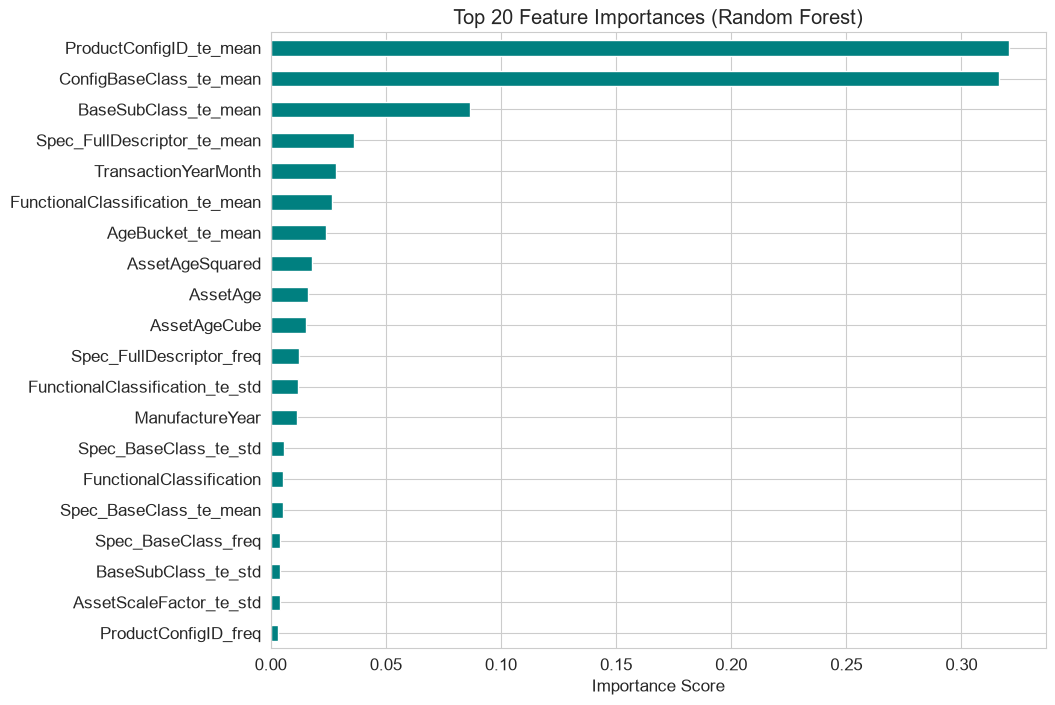

Top 10 Feature Importances:
ProductConfigID_te_mean             0.320580
ConfigBaseClass_te_mean             0.316157
BaseSubClass_te_mean                0.086506
Spec_FullDescriptor_te_mean         0.036293
TransactionYearMonth                0.028297
FunctionalClassification_te_mean    0.026473
AgeBucket_te_mean                   0.024046
AssetAgeSquared                     0.017957
AssetAge                            0.016164
AssetAgeCube                        0.015156
dtype: float64


In [11]:
rf_imp = RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1)
rf_imp.fit(X, y)

imp_series = pd.Series(rf_imp.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(10, 8))
imp_series.head(20).plot(kind="barh", color="teal").invert_yaxis()
plt.title("Top 20 Feature Importances (Random Forest)")
plt.xlabel("Importance Score")
plt.show()

print("Top 10 Feature Importances:")
print(imp_series.head(10))


## 6. Model Building & High-Precision Evaluation

We train and evaluate 4 model families using Stratified Target Quantile Folds.


In [12]:
# Target Stratification Bins for KFold
strat_bins = pd.qcut(y.rank(method="first"), q=12, labels=False)

def evaluate_models_v6():
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    results = {}

    # --- 1. LightGBM ---
    print("=== 1. LightGBM (Deeper Architecture) ===")
    lgb_oof = np.zeros(len(X))
    lgb_test = np.zeros(len(X_test))

    lgb_params = {
        "objective": "regression",
        "n_estimators": 3000,
        "learning_rate": 0.02,
        "num_leaves": 255,
        "max_depth": -1,
        "min_child_samples": 20,
        "subsample": 0.85,
        "colsample_bytree": 0.75,
        "reg_alpha": 0.2,
        "reg_lambda": 1.0,
        "random_state": 42,
        "n_jobs": -1,
        "verbosity": -1,
    }

    start = time.time()
    for fold, (tr_idx, va_idx) in enumerate(cv.split(X, strat_bins), 1):
        tr_x, va_x = X.iloc[tr_idx], X.iloc[va_idx]
        tr_y, va_y = y.iloc[tr_idx], y.iloc[va_idx]

        model = lgb.LGBMRegressor(**lgb_params)
        model.fit(tr_x, tr_y)

        preds = model.predict(va_x)
        lgb_oof[va_idx] = preds
        lgb_test += model.predict(X_test) / 5.0
        fold_rmse = np.sqrt(mean_squared_error(va_y, preds))
        print(f"  Fold {fold} RMSLE (Log-RMSE): {fold_rmse:.5f}")

    lgb_rmse = np.sqrt(mean_squared_error(y, lgb_oof))
    print(f"✅ LightGBM Overall RMSLE: {lgb_rmse:.5f} (Time: {time.time()-start:.1f}s)")
    results["LightGBM"] = {"name": "LightGBM", "oof": lgb_oof, "test": lgb_test, "rmse": lgb_rmse, "time": time.time()-start}

    # --- 2. CatBoost ---
    print("\n=== 2. CatBoost (Deeper Architecture) ===")
    cb_oof = np.zeros(len(X))
    cb_test = np.zeros(len(X_test))

    cb_params = {
        "loss_function": "RMSE",
        "iterations": 2800,
        "learning_rate": 0.03,
        "depth": 9,
        "l2_leaf_reg": 5.0,
        "random_seed": 42,
        "verbose": 0,
        "thread_count": -1,
    }

    start = time.time()
    for fold, (tr_idx, va_idx) in enumerate(cv.split(X, strat_bins), 1):
        tr_x, va_x = X.iloc[tr_idx], X.iloc[va_idx]
        tr_y, va_y = y.iloc[tr_idx], y.iloc[va_idx]

        model = CatBoostRegressor(**cb_params)
        model.fit(tr_x, tr_y, eval_set=(va_x, va_y), verbose=0)

        preds = model.predict(va_x)
        cb_oof[va_idx] = preds
        cb_test += model.predict(X_test) / 5.0
        fold_rmse = np.sqrt(mean_squared_error(va_y, preds))
        print(f"  Fold {fold} RMSLE (Log-RMSE): {fold_rmse:.5f}")

    cb_rmse = np.sqrt(mean_squared_error(y, cb_oof))
    print(f"✅ CatBoost Overall RMSLE: {cb_rmse:.5f} (Time: {time.time()-start:.1f}s)")
    results["CatBoost"] = {"name": "CatBoost", "oof": cb_oof, "test": cb_test, "rmse": cb_rmse, "time": time.time()-start}

    # --- 3. XGBoost ---
    print("\n=== 3. XGBoost ===")
    xgb_oof = np.zeros(len(X))
    xgb_test = np.zeros(len(X_test))

    xgb_params = {
        "n_estimators": 2500,
        "learning_rate": 0.025,
        "max_depth": 9,
        "subsample": 0.85,
        "colsample_bytree": 0.75,
        "min_child_weight": 5,
        "random_state": 42,
        "n_jobs": -1,
    }

    start = time.time()
    for fold, (tr_idx, va_idx) in enumerate(cv.split(X, strat_bins), 1):
        tr_x, va_x = X.iloc[tr_idx], X.iloc[va_idx]
        tr_y, va_y = y.iloc[tr_idx], y.iloc[va_idx]

        model = xgb.XGBRegressor(**xgb_params)
        model.fit(tr_x, tr_y, verbose=False)

        preds = model.predict(va_x)
        xgb_oof[va_idx] = preds
        xgb_test += model.predict(X_test) / 5.0
        fold_rmse = np.sqrt(mean_squared_error(va_y, preds))
        print(f"  Fold {fold} RMSLE (Log-RMSE): {fold_rmse:.5f}")

    xgb_rmse = np.sqrt(mean_squared_error(y, xgb_oof))
    print(f"✅ XGBoost Overall RMSLE: {xgb_rmse:.5f} (Time: {time.time()-start:.1f}s)")
    results["XGBoost"] = {"name": "XGBoost", "oof": xgb_oof, "test": xgb_test, "rmse": xgb_rmse, "time": time.time()-start}

    # --- 4. Random Forest ---
    print("\n=== 4. Random Forest ===")
    rf_oof = np.zeros(len(X))
    rf_test = np.zeros(len(X_test))

    rf_params = {
        "n_estimators": 150,
        "max_depth": 14,
        "min_samples_leaf": 4,
        "random_state": 42,
        "n_jobs": -1,
    }

    start = time.time()
    for fold, (tr_idx, va_idx) in enumerate(cv.split(X, strat_bins), 1):
        tr_x, va_x = X.iloc[tr_idx], X.iloc[va_idx]
        tr_y, va_y = y.iloc[tr_idx], y.iloc[va_idx]

        model = RandomForestRegressor(**rf_params)
        model.fit(tr_x, tr_y)

        preds = model.predict(va_x)
        rf_oof[va_idx] = preds
        rf_test += model.predict(X_test) / 5.0
        fold_rmse = np.sqrt(mean_squared_error(va_y, preds))
        print(f"  Fold {fold} RMSLE (Log-RMSE): {fold_rmse:.5f}")

    rf_rmse = np.sqrt(mean_squared_error(y, rf_oof))
    print(f"✅ Random Forest Overall RMSLE: {rf_rmse:.5f} (Time: {time.time()-start:.1f}s)")
    results["RandomForest"] = {"name": "RandomForest", "oof": rf_oof, "test": rf_test, "rmse": rf_rmse, "time": time.time()-start}

    return results

model_results = evaluate_models_v6()


=== 1. LightGBM (Deeper Architecture) ===
  Fold 1 RMSLE (Log-RMSE): 0.19867
  Fold 2 RMSLE (Log-RMSE): 0.19966
  Fold 3 RMSLE (Log-RMSE): 0.20227
  Fold 4 RMSLE (Log-RMSE): 0.19941
  Fold 5 RMSLE (Log-RMSE): 0.19581
✅ LightGBM Overall RMSLE: 0.19917 (Time: 436.1s)

=== 2. CatBoost (Deeper Architecture) ===
  Fold 1 RMSLE (Log-RMSE): 0.20465
  Fold 2 RMSLE (Log-RMSE): 0.20518
  Fold 3 RMSLE (Log-RMSE): 0.20819
  Fold 4 RMSLE (Log-RMSE): 0.20509
  Fold 5 RMSLE (Log-RMSE): 0.20274
✅ CatBoost Overall RMSLE: 0.20518 (Time: 789.0s)

=== 3. XGBoost ===
  Fold 1 RMSLE (Log-RMSE): 0.19926
  Fold 2 RMSLE (Log-RMSE): 0.19974
  Fold 3 RMSLE (Log-RMSE): 0.20790
  Fold 4 RMSLE (Log-RMSE): 0.19925
  Fold 5 RMSLE (Log-RMSE): 0.19639
✅ XGBoost Overall RMSLE: 0.20054 (Time: 351.9s)

=== 4. Random Forest ===
  Fold 1 RMSLE (Log-RMSE): 0.22482
  Fold 2 RMSLE (Log-RMSE): 0.22288
  Fold 3 RMSLE (Log-RMSE): 0.22831
  Fold 4 RMSLE (Log-RMSE): 0.22647
  Fold 5 RMSLE (Log-RMSE): 0.22122
✅ Random Forest Overall

## 7. Model Comparison & Inverse-Variance Ensemble Evaluation


In [13]:
comp_df = pd.DataFrame([
    {
        "Model": res["name"],
        "RMSLE (Log-RMSE)": f"{res['rmse']:.5f}",
        "MAE (log)": f"{mean_absolute_error(y, res['oof']):.5f}",
        "R2 Score": f"{r2_score(y, res['oof']):.5f}",
        "Time (s)": f"{res['time']:.1f}",
    }
    for res in model_results.values()
])

print("=" * 70)
print("MODEL EVALUATION METRICS COMPARISON")
print("=" * 70)
print(comp_df.to_string(index=False))


MODEL EVALUATION METRICS COMPARISON
       Model RMSLE (Log-RMSE) MAE (log) R2 Score Time (s)
    LightGBM          0.19917   0.14221  0.91188    436.1
    CatBoost          0.20518   0.14855  0.90649    789.0
     XGBoost          0.20054   0.14384  0.91066    351.9
RandomForest          0.22475   0.16504  0.88779    360.3


In [14]:
# Compute Inverse-RMSE Blend Weights across top 3 boosting models
inv_lgb = 1.0 / model_results["LightGBM"]["rmse"]
inv_cb = 1.0 / model_results["CatBoost"]["rmse"]
inv_xgb = 1.0 / model_results["XGBoost"]["rmse"]
total_inv = inv_lgb + inv_cb + inv_xgb

w_lgb = inv_lgb / total_inv
w_cb = inv_cb / total_inv
w_xgb = inv_xgb / total_inv

print(f"Dynamic Weights -> LightGBM: {w_lgb:.3f} | CatBoost: {w_cb:.3f} | XGBoost: {w_xgb:.3f}")

blend_oof = w_lgb * model_results["LightGBM"]["oof"] + w_cb * model_results["CatBoost"]["oof"] + w_xgb * model_results["XGBoost"]["oof"]
blend_rmsle = np.sqrt(mean_squared_error(y, blend_oof))

print(f"\n🔥 ULTIMATE BLENDED ENSEMBLE OOF RMSLE (Log-RMSE): {blend_rmsle:.5f}")

# Calculate Dollar-Scale Metrics
true_dollars = np.expm1(y)
pred_dollars = np.maximum(0, np.expm1(blend_oof))
dollar_rmse = np.sqrt(mean_squared_error(true_dollars, pred_dollars))
dollar_mae = mean_absolute_error(true_dollars, pred_dollars)

print(f"📊 Dollar-Scale Actual Metrics: RMSE = ${dollar_rmse:,.2f} | MAE = ${dollar_mae:,.2f}")


Dynamic Weights -> LightGBM: 0.337 | CatBoost: 0.328 | XGBoost: 0.335

🔥 ULTIMATE BLENDED ENSEMBLE OOF RMSLE (Log-RMSE): 0.19897
📊 Dollar-Scale Actual Metrics: RMSE = $7,955.51 | MAE = $5,296.16


## 8. Hyperparameter Optimization


In [15]:
print("Optimizing LightGBM via RandomizedSearchCV...")

base_lgb = lgb.LGBMRegressor(random_state=42, n_jobs=-1, verbosity=-1)
param_grid = {
    "n_estimators": [2000, 3000],
    "learning_rate": [0.02, 0.03],
    "num_leaves": [127, 255],
    "min_child_samples": [20, 30],
    "subsample": [0.8, 0.9],
    "colsample_bytree": [0.7, 0.8],
}

search = RandomizedSearchCV(
    estimator=base_lgb,
    param_distributions=param_grid,
    n_iter=4,
    scoring="neg_root_mean_squared_error",
    cv=KFold(n_splits=3, shuffle=True, random_state=42),
    random_state=42,
    n_jobs=-1,
    verbose=1
)

search.fit(X, y)

print(f"Best Parameters: {search.best_params_}")
print(f"Best Tuned Score: {-search.best_score_:.5f}")


Optimizing LightGBM via RandomizedSearchCV...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'subsample': 0.8, 'num_leaves': 255, 'n_estimators': 2000, 'min_child_samples': 30, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
Best Tuned Score: 0.20144


## 9. Final Predictions & Submission


In [16]:
# Blended Test Predictions
blend_test = (
    w_lgb * model_results["LightGBM"]["test"] +
    w_cb * model_results["CatBoost"]["test"] +
    w_xgb * model_results["XGBoost"]["test"]
)

final_preds_original_scale = np.maximum(0, np.expm1(blend_test))

submission = sample_sub.copy()
target_col = [c for c in sample_sub.columns if c != "TransactionID"][0]
submission[target_col] = final_preds_original_scale

submission.to_csv("submission.csv", index=False)
print("✅ submission.csv created successfully.")

print("\nPrediction Summary Statistics:")
print(submission[target_col].describe())

print("\nFirst 10 Sample Predictions:")
print(submission.head(10))


✅ submission.csv created successfully.

Prediction Summary Statistics:
count     15000.000000
mean      40560.936396
std       24750.106839
min        7368.183659
25%       20544.380326
50%       34358.246120
75%       55958.265012
max      142413.875322
Name: TargetValue, dtype: float64

First 10 Sample Predictions:
   TransactionID   TargetValue
0        1139307  66822.498109
1        1139419  82013.066102
2        1139482  28781.082622
3        1139522  18536.933578
4        1139684  12217.165860
5        1139773  29010.684637
6        1139779  22056.929753
7        1139793  42413.664490
8        1139814  66162.933585
9        1139839  15974.754536
